## 1. Imports and configuration

In [1]:
from pathlib import Path
import warnings
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, accuracy_score,
    roc_auc_score, average_precision_score, RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_SPLITS = 5
SCORING = "average_precision"

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

## 2. Load the dataset

In [2]:
DATA_FILENAME = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
candidate_paths = [
    Path("data") / DATA_FILENAME,
    Path(DATA_FILENAME),
    Path("../data") / DATA_FILENAME,
]

DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not find {DATA_FILENAME}. Place it in the project's data/ folder "
        "or update DATA_PATH to its location."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH.resolve()}")
print("Shape:", df.shape)
display(df.head())

Loaded: C:\Files\Learning\Projects\customer-churn-prediction\data\WA_Fn-UseC_-Telco-Customer-Churn.csv
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Data validation and cleaning

`customerID` is an identifier, not a predictive feature. Empty strings in `TotalCharges` are converted to missing values, then to 0 for records with no tenure (the dataset's zero-tenure records represent no accumulated charges). The target is explicitly mapped to 0/1.

In [3]:
required_columns = {
    "customerID", "gender", "SeniorCitizen", "Partner", "Dependents",
    "tenure", "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling",
    "PaymentMethod", "MonthlyCharges", "TotalCharges", "Churn"
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing expected columns: {sorted(missing_columns)}")

data = df.copy()
data = data.drop_duplicates()
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"].replace(r"^\\s*$", np.nan, regex=True), errors="coerce")

# In this dataset, blank TotalCharges correspond to customers with zero tenure.
zero_tenure_mask = data["tenure"].eq(0)
data.loc[zero_tenure_mask & data["TotalCharges"].isna(), "TotalCharges"] = 0

# Any remaining missing numeric values are handled by the numeric imputer in the pipeline.
data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})
if data["Churn"].isna().any():
    raise ValueError("Unexpected values found in Churn target.")

data = data.drop(columns=["customerID"])
print("Shape after duplicate removal:", data.shape)
print("\nMissing values:")
display(data.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\nTarget distribution:")
display(data["Churn"].value_counts().rename(index={0: "No churn", 1: "Churn"}).to_frame("count"))

Shape after duplicate removal: (7043, 20)

Missing values:


,missing_count
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0



Target distribution:


,count
Churn,
No churn,5174
Churn,1869


## 4. Exploratory data analysis

Overall churn rate: 26.5%


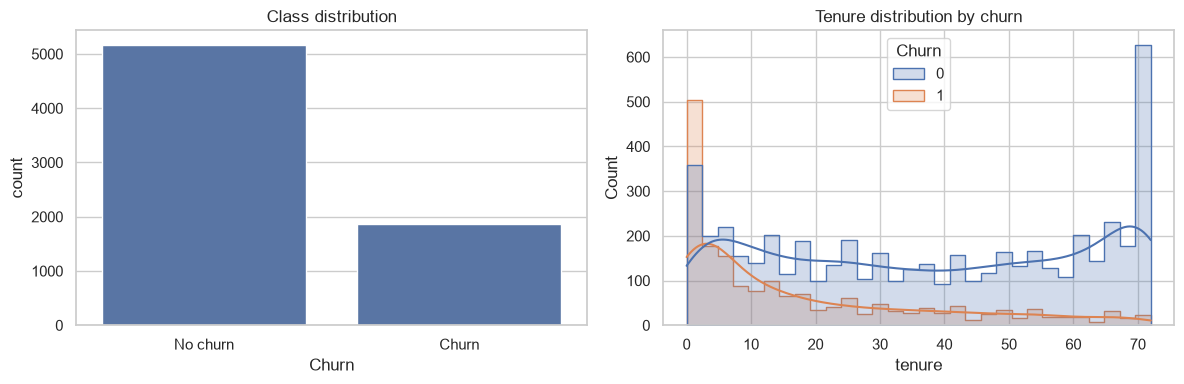

In [4]:
target_rate = data["Churn"].mean()
print(f"Overall churn rate: {target_rate:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=data, x="Churn", ax=axes[0])
axes[0].set_xticks([0, 1], ["No churn", "Churn"])
axes[0].set_title("Class distribution")
sns.histplot(data=data, x="tenure", hue="Churn", bins=30, kde=True, ax=axes[1], element="step")
axes[1].set_title("Tenure distribution by churn")
plt.tight_layout()
plt.show()

tenure        MonthlyCharges        TotalCharges         
      median   mean         median   mean       median     mean
Churn                                                          
0       38.0  37.57          64.43  61.27      1679.52  2549.91
1       10.0  17.98          79.65  74.44       703.55  1531.80

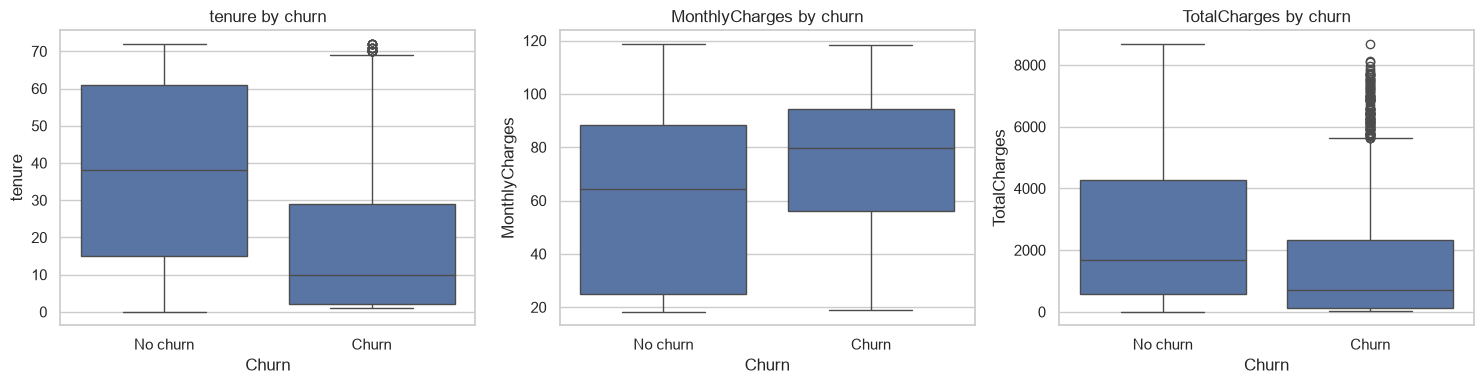

In [5]:
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]
display(data.groupby("Churn")[numeric_columns].agg(["median", "mean"]).round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric_columns):
    sns.boxplot(data=data, x="Churn", y=col, ax=ax)
    ax.set_xticks([0, 1], ["No churn", "Churn"])
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.show()

C:\Users\Vineeth\AppData\Local\Temp\ipykernel_29560\1340505708.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = data.select_dtypes(include=["object", "category"]).columns.tolist()


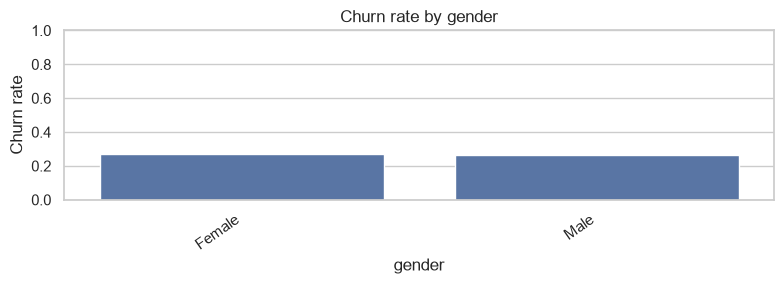

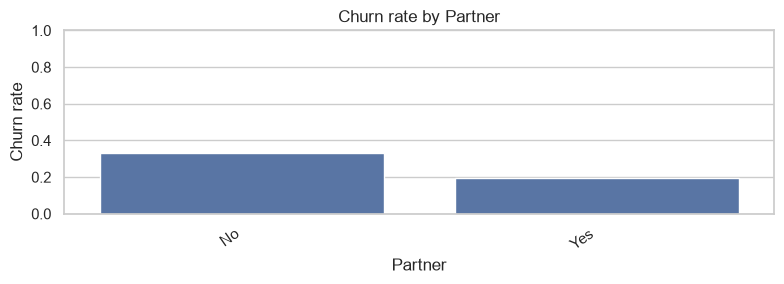

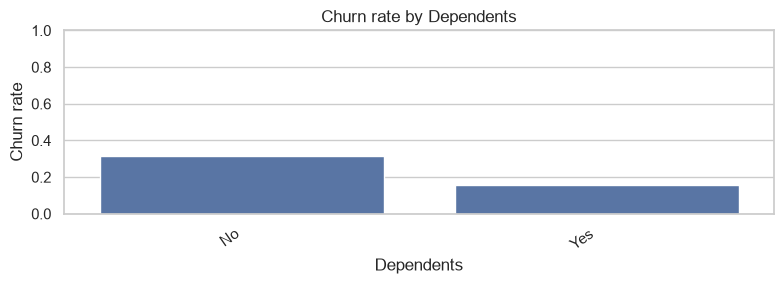

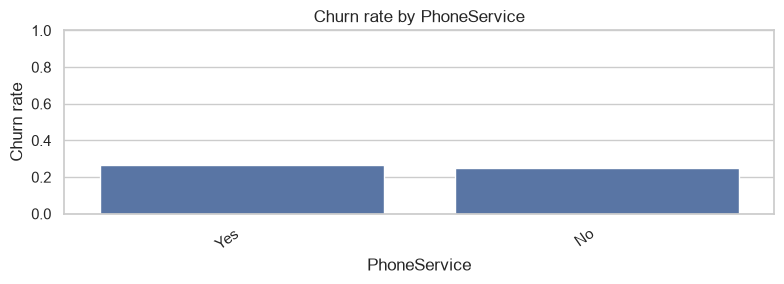

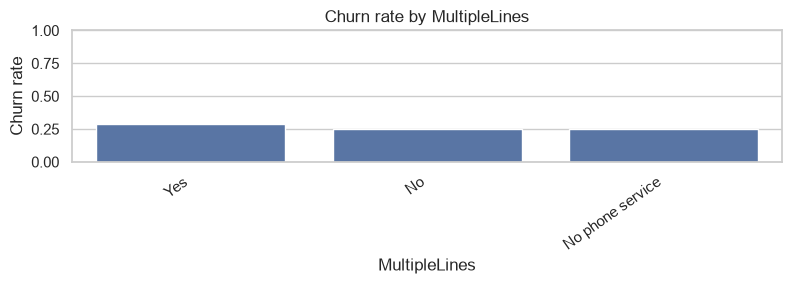

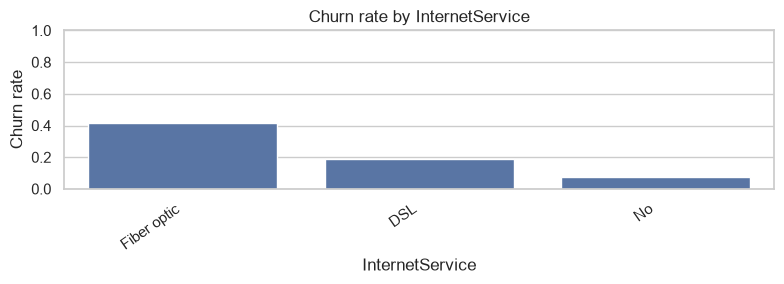

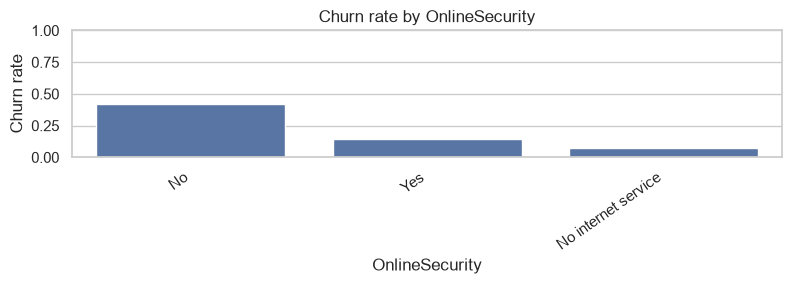

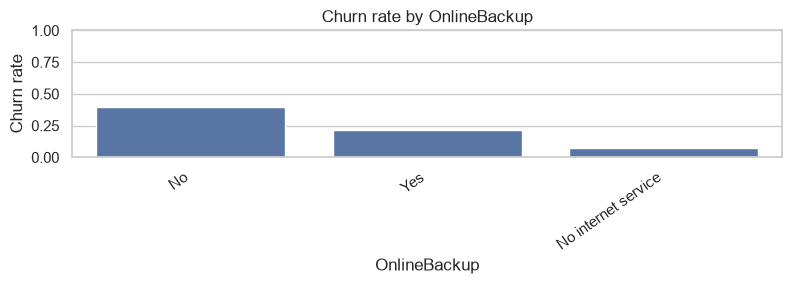

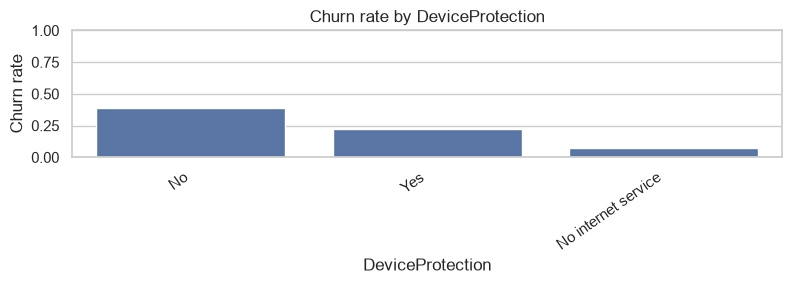

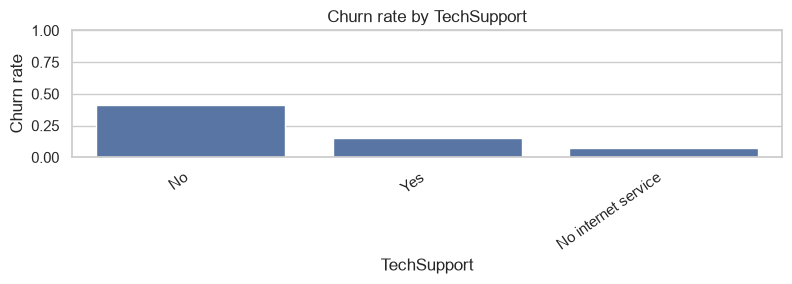

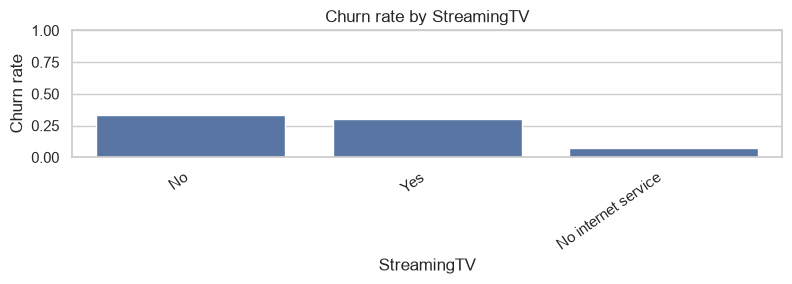

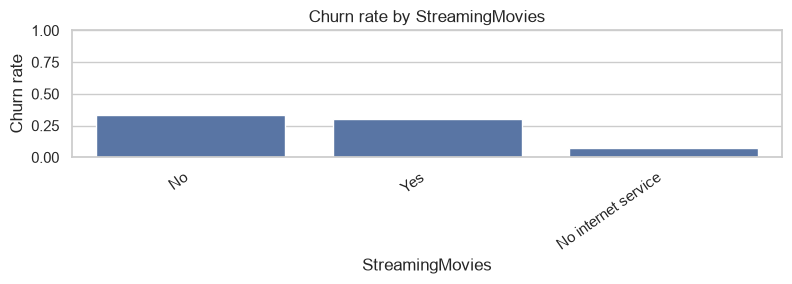

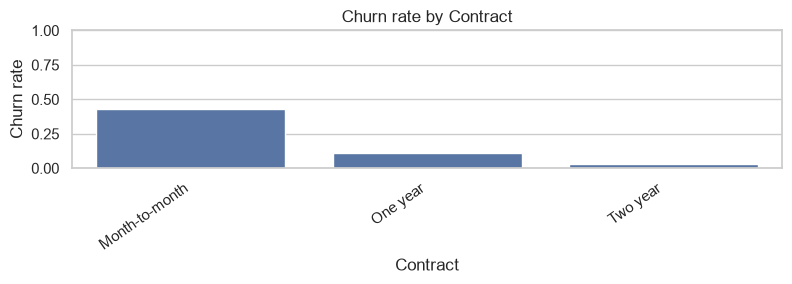

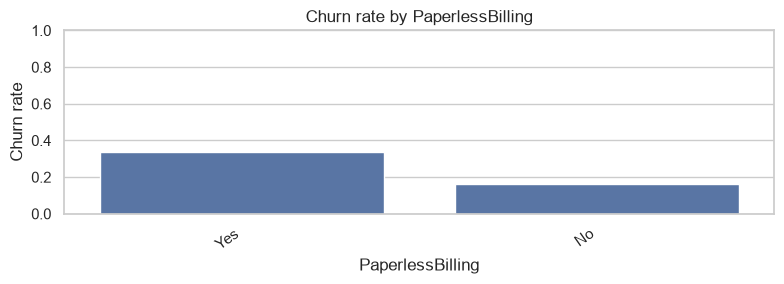

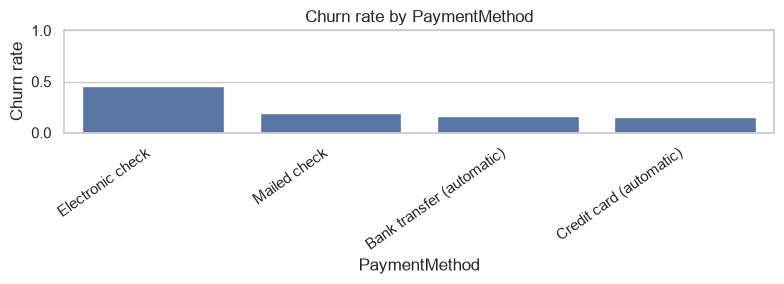

In [6]:
categorical_columns = data.select_dtypes(include=["object", "category"]).columns.tolist()
for col in categorical_columns:
    rate = data.groupby(col, dropna=False)["Churn"].mean().sort_values(ascending=False)
    plt.figure(figsize=(8, 3))
    sns.barplot(x=rate.index.astype(str), y=rate.values)
    plt.title(f"Churn rate by {col}")
    plt.ylabel("Churn rate")
    plt.xlabel(col)
    plt.xticks(rotation=35, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

## 5. Define features and make a stratified hold-out split

The test set is set aside before model fitting, preprocessing, resampling or hyperparameter tuning. It is only used for the final evaluation.

In [7]:
X = data.drop(columns="Churn")
y = data["Churn"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Training churn rate:", f"{y_train.mean():.1%}")
print("Test churn rate:", f"{y_test.mean():.1%}")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Training rows: 5634 | Test rows: 1409
Training churn rate: 26.5%
Test churn rate: 26.5%
Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 6. Preprocessing and leakage-safe resampling

- Numeric columns: median imputation and standardization.
- Categorical columns: most-frequent imputation and one-hot encoding.
- SMOTE is applied **after preprocessing and inside the imbalanced-learn pipeline**. During cross-validation, each fold fits preprocessing and generates synthetic observations using only that fold's training partition.

SMOTE after one-hot encoding can create fractional values across encoded categories. This is a commonly used practical baseline, but it is not a perfect representation of categorical data. For a stricter categorical approach, compare `SMOTENC` in a separate experiment.

In [8]:
try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # compatibility with older scikit-learn
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=False)

numeric_transformer = SklearnPipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = SklearnPipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", one_hot)
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
], remainder="drop")

## 7. Baseline and candidate models

The baseline is Logistic Regression. Decision Tree and Random Forest provide non-linear comparisons. XGBoost is included when installed; otherwise the notebook continues without it.

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
}

try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric="logloss",
        n_jobs=-1
    )
except ImportError:
    print("XGBoost is not installed; skipping it. Install xgboost to include this candidate.")

cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)

In [10]:
baseline_results = []
baseline_estimators = {}

for name, classifier in models.items():
    pipeline = ImbPipeline(steps=[
        ("preprocess", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", classifier)
    ])
    from sklearn.model_selection import cross_validate
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv,
        scoring={"average_precision": "average_precision", "recall": "recall",
                 "precision": "precision", "f1": "f1", "roc_auc": "roc_auc"},
        n_jobs=-1, error_score="raise"
    )
    baseline_estimators[name] = pipeline
    baseline_results.append({
        "Model": name,
        **{metric: scores[f"test_{metric}"].mean() for metric in
           ["average_precision", "recall", "precision", "f1", "roc_auc"]}
    })

baseline_df = pd.DataFrame(baseline_results).sort_values("average_precision", ascending=False)
display(baseline_df.round(4))

,Model,average_precision,recall,precision,f1,roc_auc
0,Logistic Regression,0.6582,0.7866,0.5272,0.6310,0.8449
3,XGBoost,0.6203,0.5645,0.5833,0.5735,0.8240
2,Random Forest,0.5912,0.5438,0.5837,0.5627,0.8158
1,Decision Tree,0.3682,0.5130,0.4646,0.4876,0.6501


## 8. Hyperparameter tuning

Each candidate is tuned on the original training split. The pipeline ensures that preprocessing and SMOTE are refitted within every fold. `average_precision` is the selection metric; the other metrics remain important diagnostics.

In [11]:
search_spaces = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 3, 10, 30],
        "model__class_weight": [None, "balanced"]
    },
    "Decision Tree": {
        "model__criterion": ["gini", "entropy", "log_loss"],
        "model__max_depth": [None, 4, 8, 12, 20, 30],
        "model__min_samples_split": [2, 5, 10, 20],
        "model__min_samples_leaf": [1, 2, 4, 8]
    },
    "Random Forest": {
        "model__n_estimators": [150, 250, 400],
        "model__max_depth": [None, 8, 12, 20, 30],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", 0.7]
    }
}
if "XGBoost" in models:
    search_spaces["XGBoost"] = {
        "model__n_estimators": [150, 250, 400],
        "model__max_depth": [2, 3, 4, 5, 7],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.7, 0.85, 1.0],
        "model__min_child_weight": [1, 3, 5]
    }

In [12]:
searches = {}
tuning_rows = []

for name, classifier in models.items():
    pipeline = ImbPipeline(steps=[
        ("preprocess", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", classifier)
    ])
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=search_spaces[name],
        n_iter=20,
        scoring=SCORING,
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
        verbose=1
    )
    print(f"\nTuning {name}...")
    search.fit(X_train, y_train)
    searches[name] = search
    tuning_rows.append({
        "Model": name,
        "Best CV average precision": search.best_score_,
        "Best parameters": search.best_params_
    })

tuning_df = pd.DataFrame(tuning_rows).sort_values("Best CV average precision", ascending=False)
display(tuning_df)


Tuning Logistic Regression...
Fitting 5 folds for each of 12 candidates, totalling 60 fits


C:\Users\Vineeth\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 12 is smaller than n_iter=20. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(



Tuning Decision Tree...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Tuning Random Forest...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Tuning XGBoost...
Fitting 5 folds for each of 20 candidates, totalling 100 fits


,Model,Best CV average precision,Best parameters
3,XGBoost,0.662308,"{'model__subsample': 0.7, 'model__n_estimators..."
0,Logistic Regression,0.658785,"{'model__class_weight': None, 'model__C': 0.01}"
2,Random Forest,0.647593,"{'model__n_estimators': 250, 'model__min_sampl..."
1,Decision Tree,0.575059,"{'model__min_samples_split': 5, 'model__min_sa..."


## 9. Select the model and evaluate once on the test set

Model selection uses the best cross-validation average-precision score. The test set is not involved in this choice. The default probability threshold is 0.50; threshold optimization can be a later business-focused step using validation data, not the test set.

In [13]:
best_name = max(searches, key=lambda name: searches[name].best_score_)
best_model = searches[best_name].best_estimator_
print("Selected model:", best_name)
print("Best CV average precision:", round(searches[best_name].best_score_, 4))

y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

test_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_proba),
    "PR-AUC (Average Precision)": average_precision_score(y_test, y_proba)
}
display(pd.Series(test_metrics, name="Test score").to_frame().round(4))
print(classification_report(y_test, y_pred, target_names=["No churn", "Churn"], zero_division=0))

Selected model: XGBoost
Best CV average precision: 0.6623


,Test score
Accuracy,0.7672
Precision,0.5446
Recall,0.7513
F1,0.6315
ROC-AUC,0.8414
PR-AUC (Average Precision),0.6422


              precision    recall  f1-score   support

    No churn       0.90      0.77      0.83      1035
       Churn       0.54      0.75      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



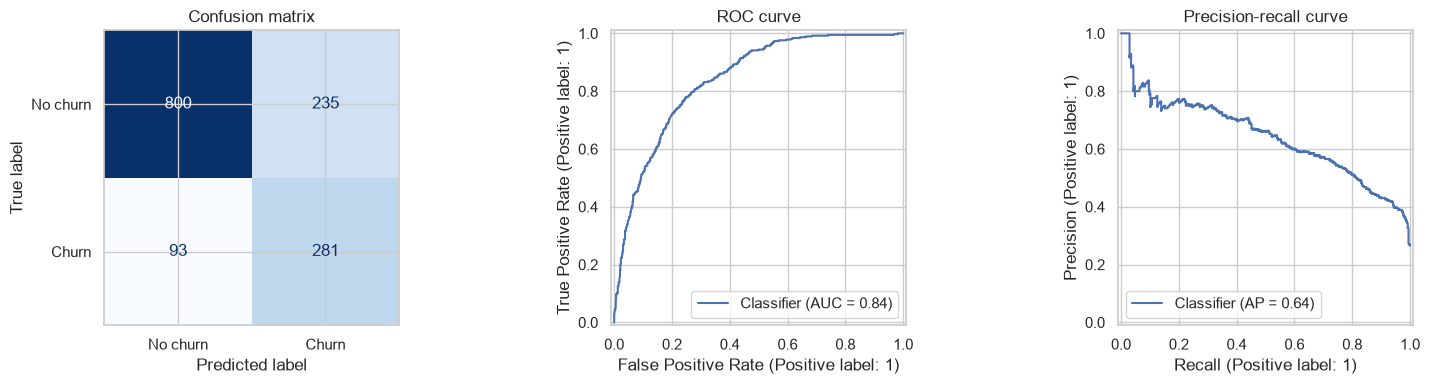

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No churn", "Churn"],
    cmap="Blues", ax=axes[0], colorbar=False
)
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[2])
axes[0].set_title("Confusion matrix")
axes[1].set_title("ROC curve")
axes[2].set_title("Precision-recall curve")
plt.tight_layout()
plt.show()

## 10. Model interpretation with permutation importance

Permutation importance measures how much the fitted model's test-set score decreases when one original input column is shuffled. It is model-agnostic and reports importance at the original feature level. Interpret it as predictive reliance, not causation.

,feature,importance_mean,importance_std
4,tenure,0.111531,0.009407
14,Contract,0.085137,0.005308
7,InternetService,0.022557,0.010723
11,TechSupport,0.017444,0.005153
8,OnlineSecurity,0.016720,0.006044
15,PaperlessBilling,0.007361,0.010128
16,PaymentMethod,0.006678,0.009906
9,OnlineBackup,0.005334,0.005002
3,Dependents,0.001139,0.004620
18,TotalCharges,0.000390,0.000483


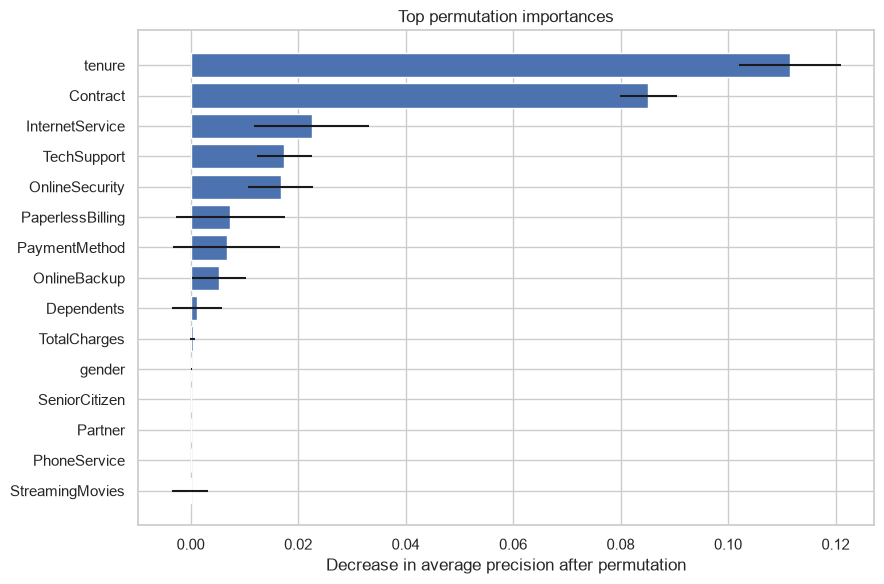

In [15]:
perm = permutation_importance(
    best_model, X_test, y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance_df)
plt.figure(figsize=(9, 6))
top = importance_df.head(15).sort_values("importance_mean")
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
plt.xlabel("Decrease in average precision after permutation")
plt.title("Top permutation importances")
plt.tight_layout()
plt.show()

## 11. Save and reload the complete pipeline

The saved object includes preprocessing, SMOTE configuration and the fitted estimator. At inference time, the pipeline applies preprocessing automatically; do not separately encode or scale customer input.

In [16]:
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODEL_DIR / "customer_churn_pipeline.joblib"

artifact = {
    "pipeline": best_model,
    "model_name": best_name,
    "feature_columns": X.columns.tolist(),
    "target_mapping": {"No": 0, "Yes": 1},
    "selection_metric": SCORING,
    "test_metrics": test_metrics
}
joblib.dump(artifact, model_path)
print("Saved model artifact to:", model_path.resolve())

loaded_artifact = joblib.load(model_path)
loaded_pipeline = loaded_artifact["pipeline"]

Saved model artifact to: C:\Files\Learning\Projects\customer-churn-prediction\notebooks\models\customer_churn_pipeline.joblib


## 12. Reusable prediction function

In [17]:
def predict_customer_churn(customer_records, pipeline=loaded_pipeline):
    """Predict churn for one customer dictionary or a list of dictionaries.

    Returns a DataFrame with predicted class and churn probability.
    Categorical values should be supplied in their original human-readable form.
    """
    records = [customer_records] if isinstance(customer_records, dict) else customer_records
    customer_df = pd.DataFrame(records)

    expected = loaded_artifact["feature_columns"]
    missing = set(expected) - set(customer_df.columns)
    extra = set(customer_df.columns) - set(expected)
    if missing:
        raise ValueError(f"Missing customer fields: {sorted(missing)}")
    if extra:
        raise ValueError(f"Unexpected customer fields: {sorted(extra)}")

    customer_df = customer_df[expected]
    probabilities = pipeline.predict_proba(customer_df)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    return pd.DataFrame({
        "prediction": np.where(predictions == 1, "Churn", "No churn"),
        "churn_probability": probabilities
    })

# Example: use one real row from the held-out set to smoke-test inference.
example_customer = X_test.iloc[0].to_dict()
predict_customer_churn(example_customer)

,prediction,churn_probability
0,No churn,0.056164
